# Decoding

In [3]:
import pandas as pd
import numpy as np
import os
import json
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from matplotlib.lines import Line2D
from sklearn.metrics import accuracy_score, f1_score
import sys
from pathlib import Path

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT.parent / 'LB'))
from src.decoding import cleandfdecodingTS

path = '/users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/ieeg_shortWOBS_fs250/BJH026_info.json'
with open(path) as json_data:
    d = json.load(json_data)
    time = d['time_epoch']

In [7]:
band = 'broadband'
method_pca = 'mean'
data_aug_method = 'mean'
PC_use = 1
model_name = 'LR'

In [8]:
train={}

file = '/users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/out/plssvd_eval_equal_var/paired_coverage/none/iteration_000/scores_000.npz'
with np.load(file,allow_pickle=False) as saved:
    train['ieeg']= saved['train_ieeg'][:, :10]
    train['meg'] = saved['train_meg'][:, :10]

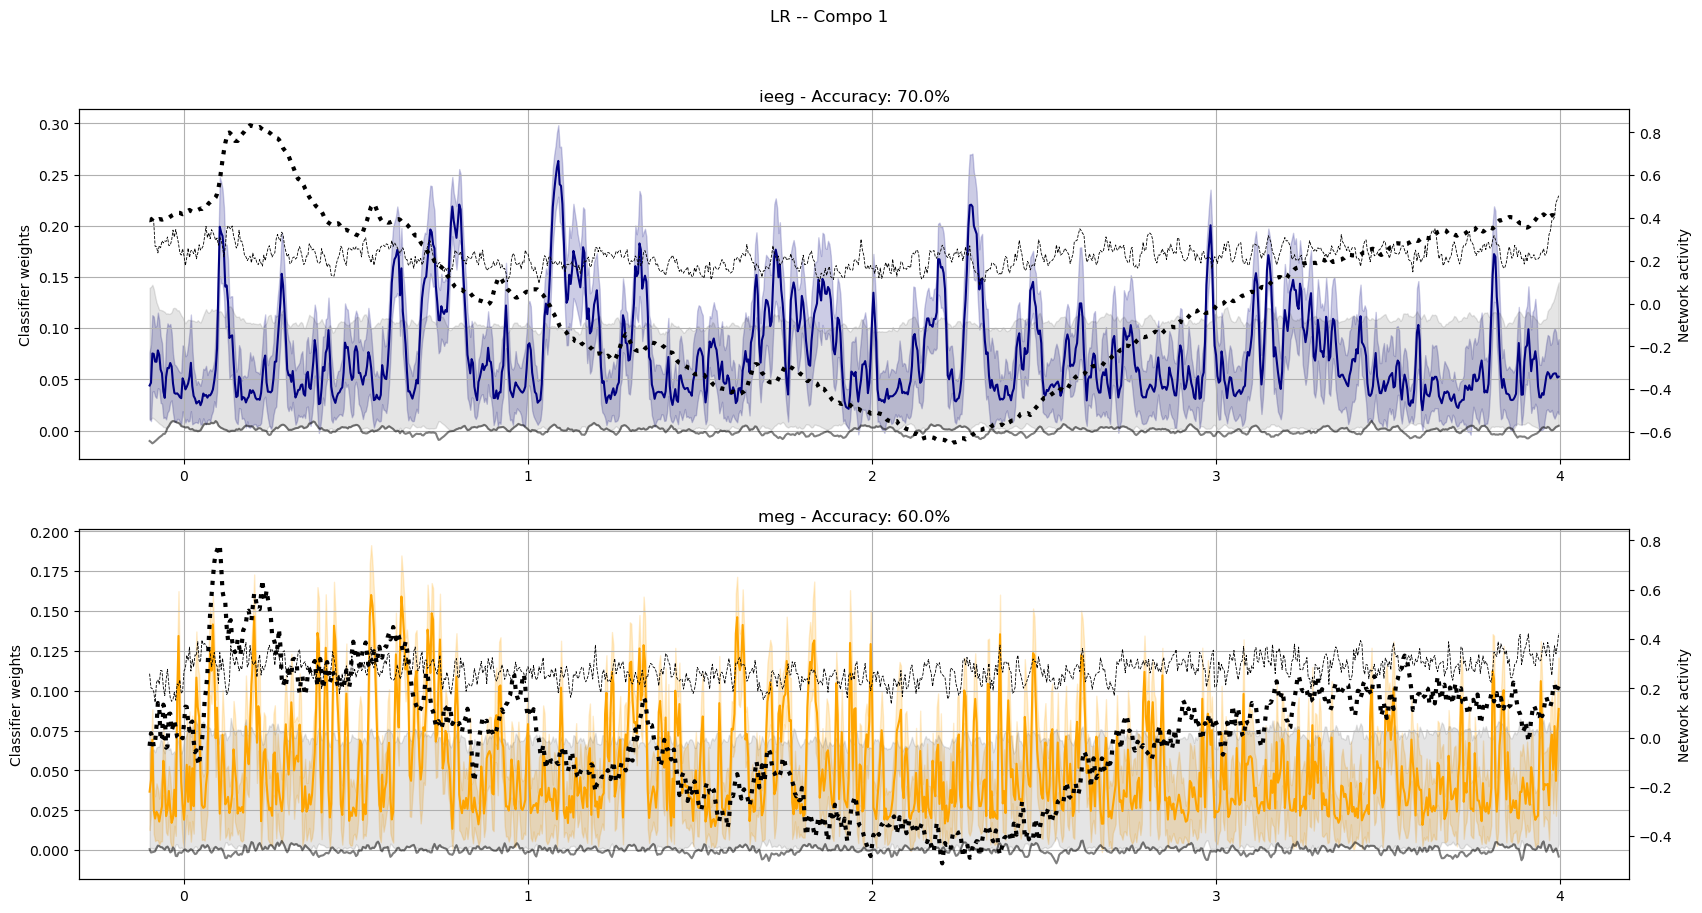

In [10]:
fig, ax = plt.subplots(2, 1, figsize=(20, 10))

color ={'ieeg' : 'navy', 'meg' : 'orange'}
fig.suptitle(f'{model_name} -- Compo 1')

for d, dataset_ in enumerate(['ieeg', 'meg']):
    df_final = pd.read_csv(f'out/decoding/{dataset_}/{band}/fullmodel/{method_pca}_{data_aug_method}_{PC_use}_{model_name}full.csv')
    result = cleandfdecodingTS(df_final, len(time))
    weight_mean= np.abs(result['weight']).mean(0)
    weight_std= np.abs(result['weight']).std(0)
    weight_sh_mean= result['weight_sh_mean']
    weight_sh_std= result['weight_sh_std']

    ax[d].plot(time, weight_mean, color=color[dataset_])
    ax[d].fill_between(time, weight_mean - weight_std,weight_mean+weight_std, alpha = 0.2, color = color[dataset_])
    
    ax[d].plot(time, weight_sh_mean, color='black',alpha=0.5,  label = f'Mean {int(df_final.loc[0, "iter_perm"])}-perm model over {int(df_final.loc[0, "iter"])} iter')
    ax[d].fill_between(time, abs(weight_sh_mean), abs(weight_sh_mean) + weight_sh_std, alpha = 0.1, color = 'black', label = f'Sd {int(df_final.loc[0, "iter_perm"])}-perm model')
    #ax[d].plot(time[20:], - np.percentile(result['weight_sh'], 95, axis=0)[20:], alpha = 1,ls='--', linewidth=0.6, color = 'black')
    ax[d].plot(time, np.percentile(result['weight_sh'], 95, axis=0), alpha = 1, ls='--', linewidth=0.6, color = 'black', label = f'95% percentil {int(df_final.loc[0, "iter_perm"])}-perm model')
    ax[d].set_ylabel('Classifier weights')
    ax[d].grid()
    ax[d].set_title(dataset_ + ' - Accuracy: ' + str(100*np.round(result['acc'], 2)) + '%')
    axt = ax[d].twinx()
    axt.set_ylabel('Network activity')
    axt.plot(time, train[dataset_][:, PC_use], ls=':', lw = 3, color='k', label = 'Network TS')

